Images found:
/content/noisy.jpg

Using image:
/content/noisy.jpg
Image loaded successfully!
Image size: (300, 332)


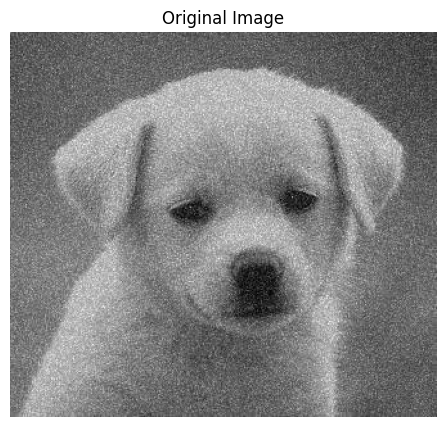

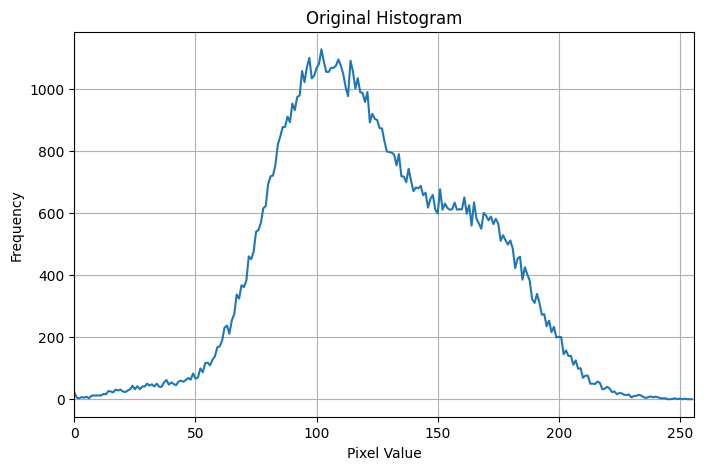

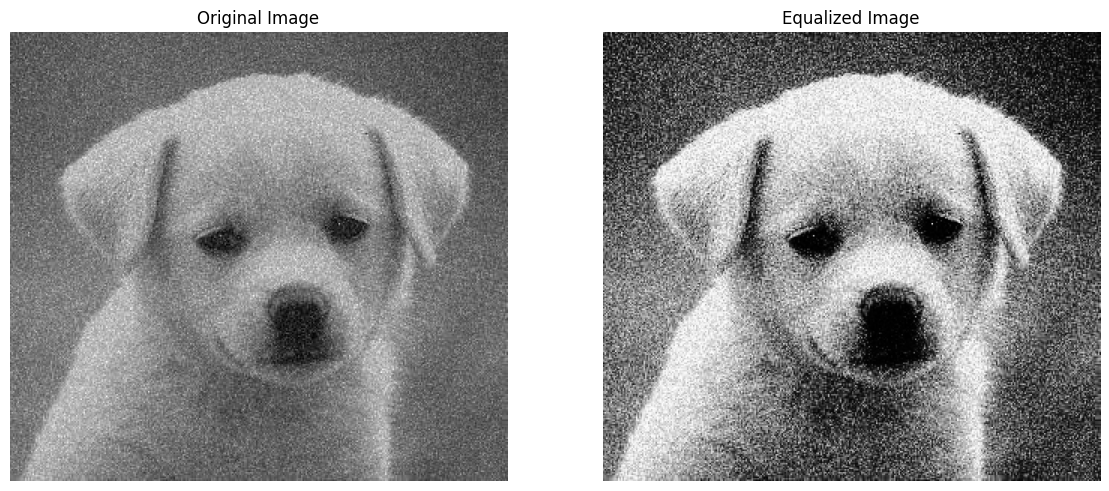

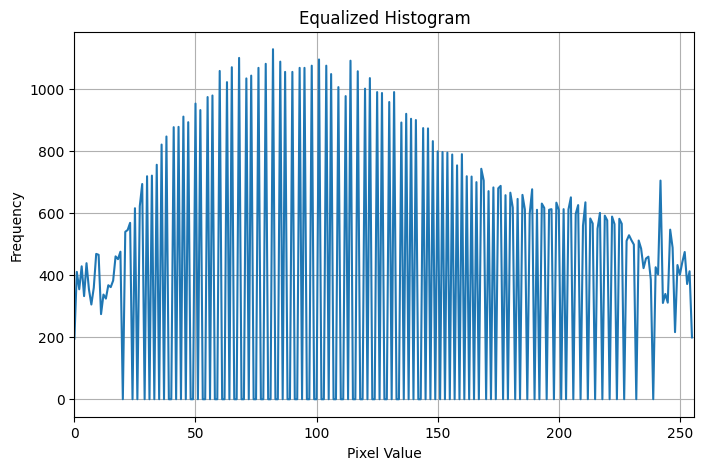

Equalized image saved as:
/content/equalized_image.jpg

No second image found.
Histogram equalization completed.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

# ==========================================
# 1. FIND IMAGE AUTOMATICALLY
# ==========================================

image_files = glob.glob("/content/*.jpg") + \
              glob.glob("/content/*.jpeg") + \
              glob.glob("/content/*.png")

if len(image_files) == 0:
    print("ERROR: No image found in /content/")
else:
    print("Images found:")
    for file in image_files:
        print(file)

    # Use the first image found
    image_path = image_files[0]

    print("\nUsing image:")
    print(image_path)

    # ==========================================
    # 2. LOAD IMAGE
    # ==========================================

    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print("ERROR: Could not read the image.")
    else:
        print("Image loaded successfully!")
        print("Image size:", image.shape)

        # ==========================================
        # 3. DISPLAY ORIGINAL IMAGE
        # ==========================================

        plt.figure(figsize=(7, 5))
        plt.imshow(image, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")
        plt.show()

        # ==========================================
        # 4. ORIGINAL HISTOGRAM
        # ==========================================

        histogram = cv2.calcHist(
            [image],
            [0],
            None,
            [256],
            [0, 256]
        )

        plt.figure(figsize=(8, 5))
        plt.plot(histogram)
        plt.title("Original Histogram")
        plt.xlabel("Pixel Value")
        plt.ylabel("Frequency")
        plt.xlim([0, 256])
        plt.grid(True)
        plt.show()

        # ==========================================
        # 5. HISTOGRAM EQUALIZATION
        # ==========================================

        equalized_image = cv2.equalizeHist(image)

        # ==========================================
        # 6. DISPLAY ORIGINAL & EQUALIZED IMAGE
        # ==========================================

        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(image, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(equalized_image, cmap="gray")
        plt.title("Equalized Image")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        # ==========================================
        # 7. EQUALIZED HISTOGRAM
        # ==========================================

        equalized_histogram = cv2.calcHist(
            [equalized_image],
            [0],
            None,
            [256],
            [0, 256]
        )

        plt.figure(figsize=(8, 5))
        plt.plot(equalized_histogram)
        plt.title("Equalized Histogram")
        plt.xlabel("Pixel Value")
        plt.ylabel("Frequency")
        plt.xlim([0, 256])
        plt.grid(True)
        plt.show()

        # ==========================================
        # 8. SAVE EQUALIZED IMAGE
        # ==========================================

        output_path = "/content/equalized_image.jpg"
        cv2.imwrite(output_path, equalized_image)

        print("Equalized image saved as:")
        print(output_path)

        # ==========================================
        # 9. HISTOGRAM MATCHING
        # ==========================================

        # Look for a reference image
        reference_files = [
            f for f in image_files
            if f != image_path
        ]

        if len(reference_files) > 0:

            reference_path = reference_files[0]

            print("\nReference image:")
            print(reference_path)

            reference_image = cv2.imread(
                reference_path,
                cv2.IMREAD_GRAYSCALE
            )

            # Source histogram
            source_hist = cv2.calcHist(
                [image],
                [0],
                None,
                [256],
                [0, 256]
            )

            # Reference histogram
            reference_hist = cv2.calcHist(
                [reference_image],
                [0],
                None,
                [256],
                [0, 256]
            )

            # Normalize
            source_hist = source_hist / source_hist.sum()
            reference_hist = reference_hist / reference_hist.sum()

            # Calculate CDF
            source_cdf = source_hist.cumsum()
            reference_cdf = reference_hist.cumsum()

            # Histogram matching
            mapping = np.interp(
                source_cdf,
                reference_cdf,
                np.arange(256)
            )

            matched_image = mapping[image]
            matched_image = matched_image.astype(np.uint8)

            # ==========================================
            # 10. DISPLAY HISTOGRAM MATCHING
            # ==========================================

            plt.figure(figsize=(15, 5))

            plt.subplot(1, 3, 1)
            plt.imshow(image, cmap="gray")
            plt.title("Source Image")
            plt.axis("off")

            plt.subplot(1, 3, 2)
            plt.imshow(reference_image, cmap="gray")
            plt.title("Reference Image")
            plt.axis("off")

            plt.subplot(1, 3, 3)
            plt.imshow(matched_image, cmap="gray")
            plt.title("Matched Image")
            plt.axis("off")

            plt.tight_layout()
            plt.show()

            # ==========================================
            # 11. SAVE MATCHED IMAGE
            # ==========================================

            matched_path = "/content/matched_output.jpg"
            cv2.imwrite(matched_path, matched_image)

            print("Matched image saved as:")
            print(matched_path)

        else:
            print("\nNo second image found.")
            print("Histogram equalization completed.")